# Data Cleaning & Exploratory Data Analysis (EDA)
## Titanic Passenger Dataset

**Objective:** inspect and clean a real-world dataset, explore distributions and relationships, identify data-quality issues, and summarize useful findings.

**Dataset:** Titanic passenger records (Seaborn's public Titanic dataset). The notebook downloads the CSV from the Seaborn-data GitHub repository, so an internet connection is required for the data-loading cell.

**Questions explored**
- What does the dataset contain, and where are its missing values?
- What were the passenger demographics and ticket/fare distributions?
- How did survival vary by sex, passenger class, age, and embarkation port?
- Which numeric features are correlated?


## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 2. Load the dataset

In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df = pd.read_csv(url)

print(f"Dataset shape: {df.shape[0]} rows × {df.shape[1]} columns")
display(df.head())

Dataset shape: 891 rows × 15 columns


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.00,1,0,7.25,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.00,1,0,71.28,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.00,0,0,7.92,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.00,1,0,53.10,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.00,0,0,8.05,S,Third,man,True,NaN,Southampton,no,True


## 3. Initial inspection

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

print("\\nNumerical summary:")
display(df.describe().T)

print("\\nCategorical summary:")
display(df.describe(include="object").T)

Column names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']
\nData types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool  

,count,mean,std,min,25%,50%,75%,max
survived,891.00,0.38,0.49,0.00,0.00,0.00,1.00,1.00
pclass,891.00,2.31,0.84,1.00,2.00,3.00,3.00,3.00
age,714.00,29.70,14.53,0.42,20.12,28.00,38.00,80.00
sibsp,891.00,0.52,1.10,0.00,0.00,0.00,1.00,8.00
parch,891.00,0.38,0.81,0.00,0.00,0.00,0.00,6.00
fare,891.00,32.20,49.69,0.00,7.91,14.45,31.00,512.33


\nCategorical summary:


,count,unique,top,freq
sex,891,2,male,577
embarked,889,3,S,644
class,891,3,Third,491
who,891,3,man,537
deck,203,7,C,59
embark_town,889,3,Southampton,644
alive,891,2,no,549


## 4. Data-quality checks

In [4]:
# Missing values
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

display(missing)

# Exact duplicate rows
duplicate_count = df.duplicated().sum()
print(f"Exact duplicate rows: {duplicate_count}")

# Cardinality and unique values
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "unique_values": df.nunique(dropna=True)
}).sort_values("unique_values"))

,missing_count,missing_percent
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22
sex,0,0.00
pclass,0,0.00
survived,0,0.00
fare,0,0.00
parch,0,0.00
sibsp,0,0.00


Exact duplicate rows: 107


,dtype,unique_values
survived,int64,2
sex,str,2
alive,str,2
adult_male,bool,2
alone,bool,2
class,str,3
pclass,int64,3
embarked,str,3
embark_town,str,3
who,str,3


### Initial data-quality observations

The Titanic data commonly contains missing values in `age`, `embarked`, and `deck`. The `deck` column has substantial missingness. We will inspect the missingness before deciding how to handle it rather than filling every missing value blindly.

## 5. Data cleaning

In [5]:
clean_df = df.copy()

# Remove exact duplicate rows, if any
clean_df = clean_df.drop_duplicates()

# Fill age using the median within passenger class and sex.
# This preserves useful demographic differences better than one global median.
clean_df["age"] = clean_df["age"].fillna(
    clean_df.groupby(["pclass", "sex"])["age"].transform("median")
)

# Fill the small number of missing embarkation values with the most frequent category.
clean_df["embarked"] = clean_df["embarked"].fillna(clean_df["embarked"].mode()[0])

# 'deck' is missing for a large proportion of passengers.
# Drop it from the main cleaned analysis rather than inventing deck values.
clean_df = clean_df.drop(columns=["deck"])

# Add readable categorical labels for analysis and plots.
clean_df["survived_label"] = clean_df["survived"].map({0: "Did not survive", 1: "Survived"})
clean_df["class_label"] = clean_df["pclass"].map({1: "First", 2: "Second", 3: "Third"})

print("Shape before cleaning:", df.shape)
print("Shape after cleaning:", clean_df.shape)
print("\\nRemaining missing values:")
display(clean_df.isna().sum().to_frame("missing_count"))

Shape before cleaning: (891, 15)
Shape after cleaning: (784, 16)
\nRemaining missing values:


,missing_count
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,0
class,0
who,0


### Cleaning decisions

- Removed exact duplicate rows, if present.
- Imputed missing ages with the median for the same `sex` and `pclass` group.
- Imputed missing `embarked` values with the mode.
- Dropped `deck` because most entries are missing; this avoids unreliable large-scale imputation.
- Kept the original `survived` and `pclass` numeric columns and added labels for clearer plots.

These are practical analysis choices, not the only possible choices. For predictive modeling, imputation should be fitted on training data only to avoid data leakage.

## 6. Univariate analysis

### Survival outcome

,passengers
survived_label,
Did not survive,461
Survived,323


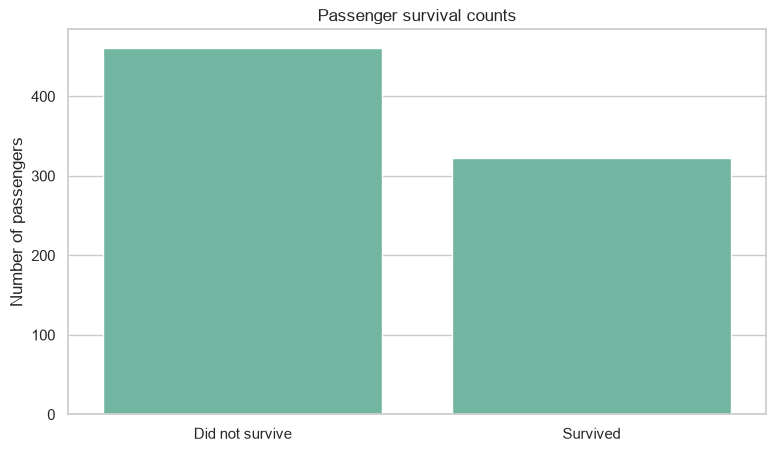

Survival rate: 41.2%


In [6]:
survival_counts = clean_df["survived_label"].value_counts()
display(survival_counts.to_frame("passengers"))

ax = sns.countplot(data=clean_df, x="survived_label", order=["Did not survive", "Survived"])
ax.set(title="Passenger survival counts", xlabel="", ylabel="Number of passengers")
plt.show()

print("Survival rate: {:.1%}".format(clean_df["survived"].mean()))

### Age and fare distributions

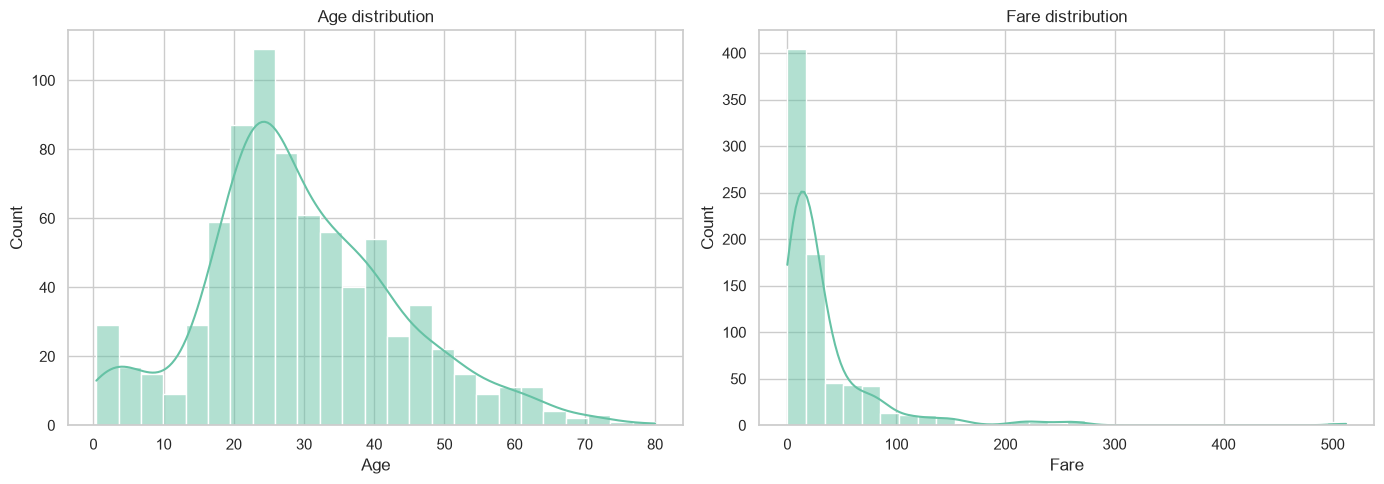

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(clean_df["age"], bins=25, kde=True, ax=axes[0])
axes[0].set(title="Age distribution", xlabel="Age")

sns.histplot(clean_df["fare"], bins=30, kde=True, ax=axes[1])
axes[1].set(title="Fare distribution", xlabel="Fare")

plt.tight_layout()
plt.show()

### Passenger class and embarkation port

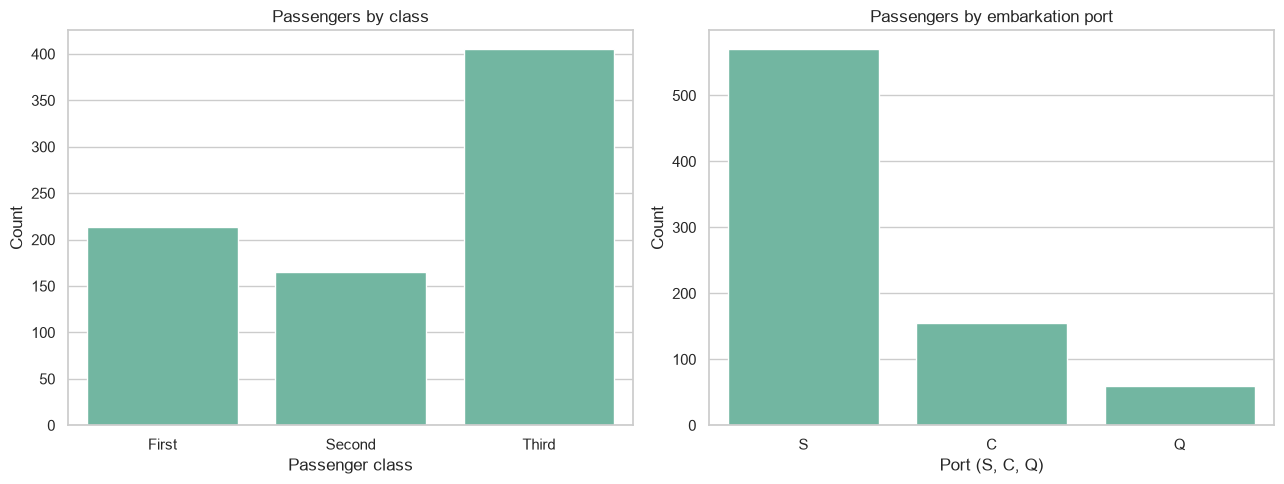

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(data=clean_df, x="class_label", order=["First", "Second", "Third"], ax=axes[0])
axes[0].set(title="Passengers by class", xlabel="Passenger class", ylabel="Count")

sns.countplot(data=clean_df, x="embarked", order=["S", "C", "Q"], ax=axes[1])
axes[1].set(title="Passengers by embarkation port", xlabel="Port (S, C, Q)", ylabel="Count")

plt.tight_layout()
plt.show()

## 7. Bivariate analysis

### Survival by sex and passenger class

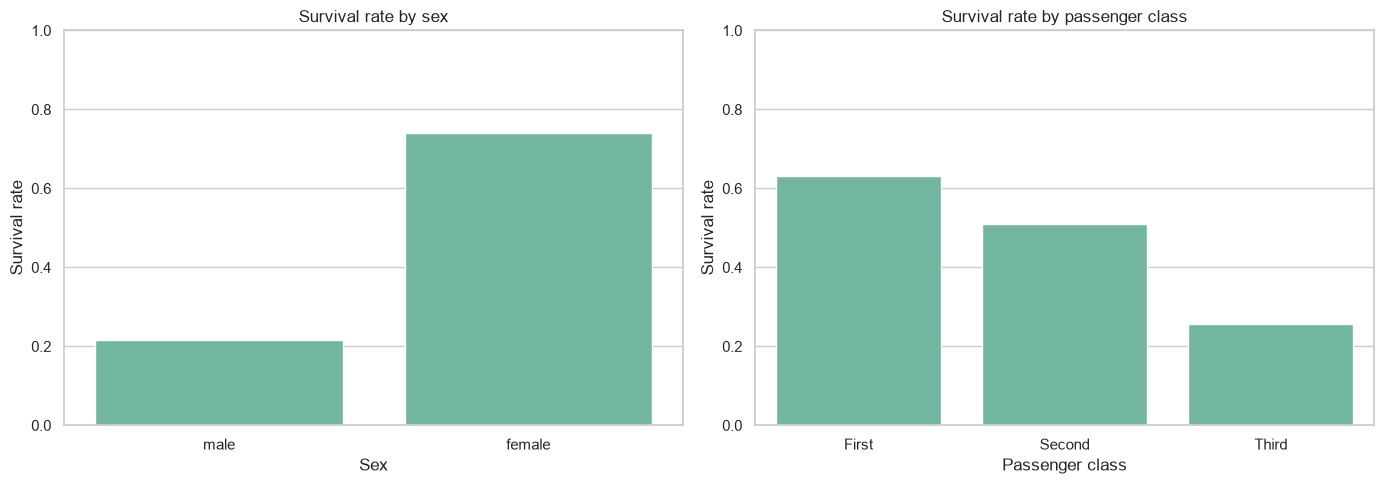

,survival_rate
sex,
female,0.74
male,0.22


,survival_rate
class_label,
First,0.63
Second,0.51
Third,0.26


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=clean_df, x="sex", y="survived", errorbar=None, ax=axes[0])
axes[0].set(title="Survival rate by sex", xlabel="Sex", ylabel="Survival rate")
axes[0].set_ylim(0, 1)

sns.barplot(
    data=clean_df, x="class_label", y="survived",
    order=["First", "Second", "Third"], errorbar=None, ax=axes[1]
)
axes[1].set(title="Survival rate by passenger class", xlabel="Passenger class", ylabel="Survival rate")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

display(clean_df.groupby("sex")["survived"].mean().rename("survival_rate").to_frame())
display(clean_df.groupby("class_label")["survived"].mean().rename("survival_rate").to_frame())

### Survival by age

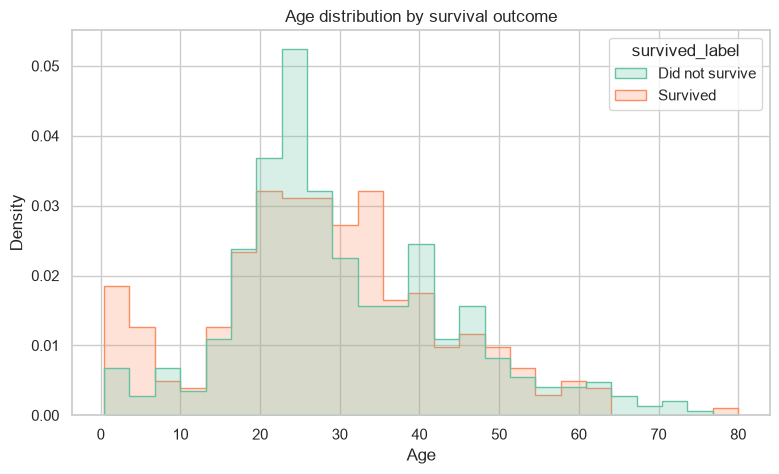

,survival_rate
age_group,
Child (0–12),0.57
Teen (13–18),0.45
Young adult (19–35),0.40
Adult (36–60),0.39
Senior (60+),0.23


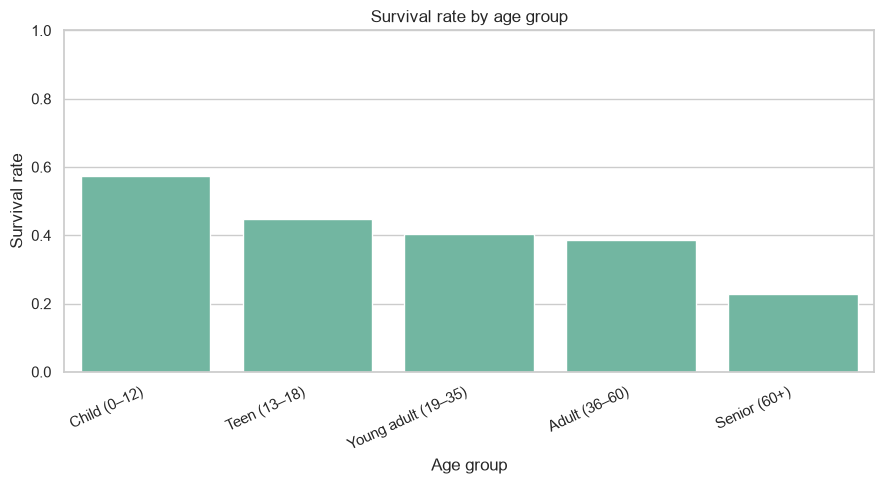

In [10]:
sns.histplot(
    data=clean_df, x="age", hue="survived_label",
    bins=25, stat="density", common_norm=False, element="step"
)
plt.title("Age distribution by survival outcome")
plt.xlabel("Age")
plt.show()

# Create age bands for an easier comparison
age_bins = [0, 12, 18, 35, 60, np.inf]
age_labels = ["Child (0–12)", "Teen (13–18)", "Young adult (19–35)", "Adult (36–60)", "Senior (60+)"]
clean_df["age_group"] = pd.cut(clean_df["age"], bins=age_bins, labels=age_labels, include_lowest=True)

age_survival = clean_df.groupby("age_group", observed=False)["survived"].mean()
display(age_survival.rename("survival_rate").to_frame())

sns.barplot(x=age_survival.index, y=age_survival.values)
plt.title("Survival rate by age group")
plt.xlabel("Age group")
plt.ylabel("Survival rate")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

### Fare by passenger class and survival

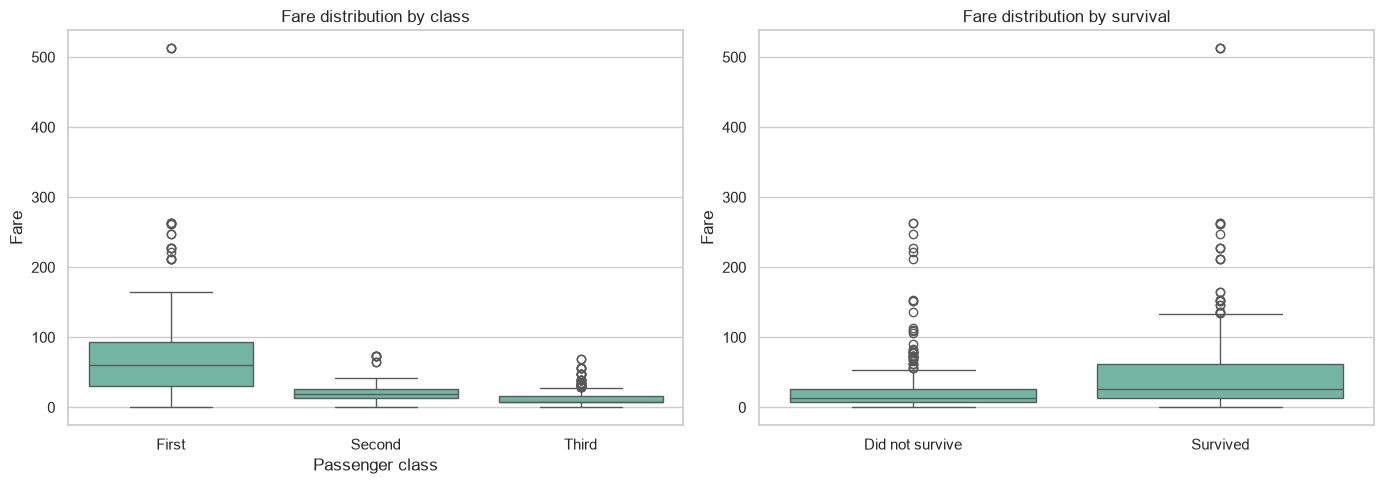

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=clean_df, x="class_label", y="fare",
            order=["First", "Second", "Third"], ax=axes[0])
axes[0].set(title="Fare distribution by class", xlabel="Passenger class", ylabel="Fare")

sns.boxplot(data=clean_df, x="survived_label", y="fare", ax=axes[1])
axes[1].set(title="Fare distribution by survival", xlabel="", ylabel="Fare")

plt.tight_layout()
plt.show()

## 8. Correlation analysis

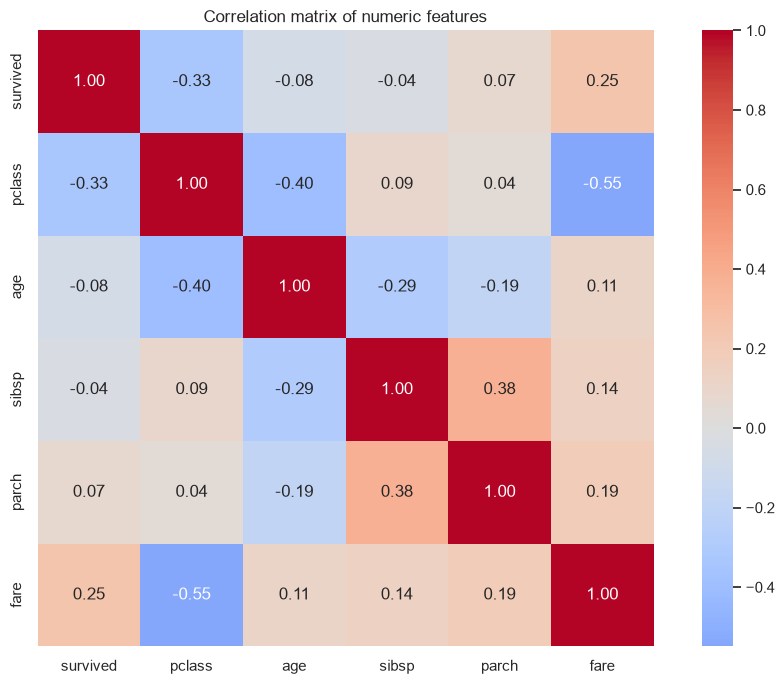

,correlation_with_survived
survived,1.00
fare,0.25
parch,0.07
sibsp,-0.04
age,-0.08
pclass,-0.33


In [12]:
numeric_cols = clean_df.select_dtypes(include=np.number)
corr = numeric_cols.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix of numeric features")
plt.tight_layout()
plt.show()

display(corr["survived"].sort_values(ascending=False).to_frame("correlation_with_survived"))

## 9. Outlier inspection

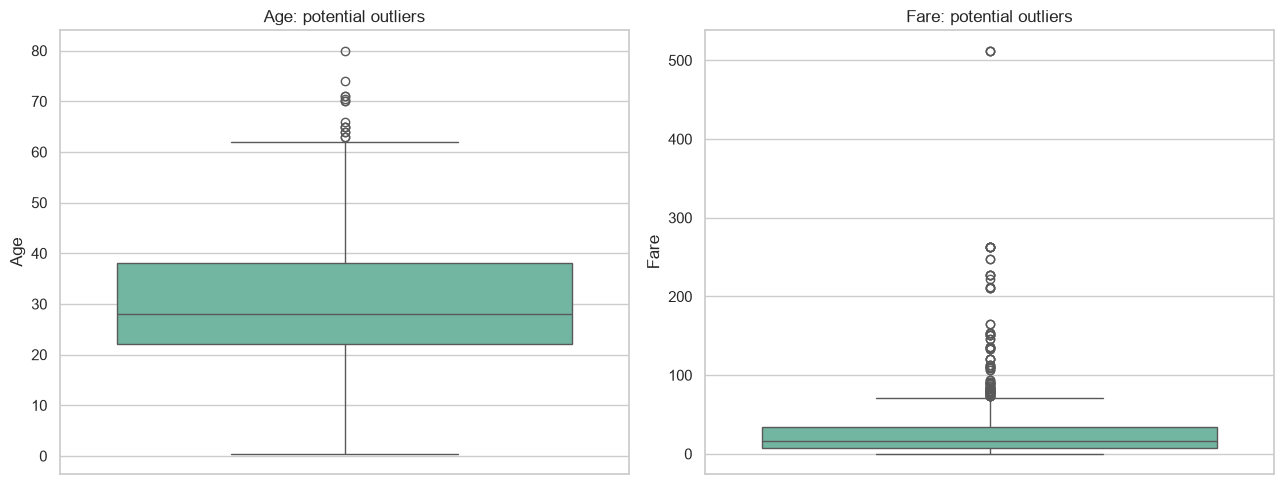

age: 15 IQR-flagged values (bounds: -2.00 to 62.00)
fare: 102 IQR-flagged values (bounds: -31.04 to 73.20)


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(y=clean_df["age"], ax=axes[0])
axes[0].set(title="Age: potential outliers", ylabel="Age")

sns.boxplot(y=clean_df["fare"], ax=axes[1])
axes[1].set(title="Fare: potential outliers", ylabel="Fare")

plt.tight_layout()
plt.show()

# IQR-based counts; these are flagged observations, not automatic errors.
def iqr_outlier_count(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return int(((series < lower) | (series > upper)).sum()), lower, upper

for column in ["age", "fare"]:
    count, lower, upper = iqr_outlier_count(clean_df[column])
    print(f"{column}: {count} IQR-flagged values (bounds: {lower:.2f} to {upper:.2f})")

**Interpretation:** unusually high fares may represent genuine first-class or group-ticket purchases, not data-entry errors. Outliers should be investigated in context and should not be deleted automatically.

## 10. Key findings (data-driven summary)

In [14]:
overall_survival = clean_df["survived"].mean()
sex_rates = clean_df.groupby("sex")["survived"].mean().sort_values(ascending=False)
class_rates = clean_df.groupby("class_label")["survived"].mean().sort_values(ascending=False)
port_counts = clean_df["embarked"].value_counts()

print(f"Overall survival rate: {overall_survival:.1%}")
print(f"Highest survival rate by sex: {sex_rates.index[0]} ({sex_rates.iloc[0]:.1%})")
print(f"Highest survival rate by passenger class: {class_rates.index[0]} ({class_rates.iloc[0]:.1%})")
print(f"Most common embarkation port: {port_counts.index[0]} ({port_counts.iloc[0]:,} passengers)")

print("\\nSurvival rates by sex:")
display((sex_rates * 100).round(1).rename("survival_rate_percent").to_frame())

print("Survival rates by class:")
display((class_rates * 100).round(1).rename("survival_rate_percent").to_frame())

Overall survival rate: 41.2%
Highest survival rate by sex: female (74.1%)
Highest survival rate by passenger class: First (63.1%)
Most common embarkation port: S (570 passengers)
\nSurvival rates by sex:


,survival_rate_percent
sex,
female,74.10
male,21.60


Survival rates by class:


,survival_rate_percent
class_label,
First,63.10
Second,50.90
Third,25.70


## 11. Conclusion

Use the outputs above to write a short conclusion in your own words. A good EDA conclusion should cover:

1. **Data quality:** which columns had missing values, and how were they handled?
2. **Distributions:** what did you notice about age, fare, passenger class, and survival?
3. **Relationships:** which passenger characteristics were associated with survival?
4. **Outliers:** which values were flagged, and are they necessarily errors?
5. **Limitations:** this is historical passenger data; associations do not prove causation, and the dataset may not represent other populations.

### Possible next steps
- Build a classification model to predict survival.
- Compare results with and without imputed rows.
- Investigate family size and whether traveling alone was associated with survival.
- Perform statistical tests before making stronger claims about group differences.
